[![Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/giordamaug/Relational_EHR_data_to_Longitudinal_Patient_Trajectories/blob/main/run_experiments.ipynb)

## Settings

In [18]:
dataset = "INA"
results_dir = "experiment_main"
iter = 10
metrics = ['AUC', 'AUPRC', 'F1', 'PPV', 'Sensitivity', 'Specificity', 'NPV', 'MCC', 'Accuracy']
methods = "STATIC STATIC+BINARY STATIC+FREQUENCY STATIC+EVENT-CNT STATIC+TF-IDF STATIC+BOW STATIC+BiPadLSTM STATIC+Med2Vec STATIC+Dipole STATIC+CEHR-BERT STATIC+DOME STATIC+GRU"

## Download files from Github

In [ ]:
try:
    import google.colab
    %mkdir data
    %mkdir scripts
    %mkdir {results_dir}
    !wget -np https://raw.githubusercontent.com/giordamaug/Relational_EHR_data_to_Longitudinal_Patient_Trajectories/main/data/{dataset}_dataset.json -O data/{dataset}_dataset.json
    !wget -np https://raw.githubusercontent.com/giordamaug/Relational_EHR_data_to_Longitudinal_Patient_Trajectories/main/scripts/models.py -O scripts/models.py
    !wget -np https://raw.githubusercontent.com/giordamaug/Relational_EHR_data_to_Longitudinal_Patient_Trajectories/main/scripts/utils.py -O scripts/utils.py
    !wget -np https://raw.githubusercontent.com/giordamaug/Relational_EHR_data_to_Longitudinal_Patient_Trajectories/main/scripts/classifiers.py -O scripts/classifiers.py
    !wget -np https://raw.githubusercontent.com/giordamaug/Relational_EHR_data_to_Longitudinal_Patient_Trajectories/main/scripts/embedding.py -O scripts/embedding.py
    !wget -np https://raw.githubusercontent.com/giordamaug/Relational_EHR_data_to_Longitudinal_Patient_Trajectories/main/scripts/cv_folding.py -O scripts/cv_folding.py
    !wget -np https://raw.githubusercontent.com/giordamaug/Relational_EHR_data_to_Longitudinal_Patient_Trajectories/main/scripts/configure.py -O scripts/configure.py
    !wget -np https://raw.githubusercontent.com/giordamaug/Relational_EHR_data_to_Longitudinal_Patient_Trajectories/main/scripts/stats.py -O scripts/stats.py
    !wget -np https://raw.githubusercontent.com/giordamaug/Relational_EHR_data_to_Longitudinal_Patient_Trajectories/main/scripts/plotting.py -O scripts/plotting.py
    !wget -np https://raw.githubusercontent.com/giordamaug/Relational_EHR_data_to_Longitudinal_Patient_Trajectories/main/metric_calculations.py -O metric_calculations.py
    !wget -np https://raw.githubusercontent.com/giordamaug/Relational_EHR_data_to_Longitudinal_Patient_Trajectories/main/notebook.py -O notebook.py
    print("Working on Colab!")
except:
    print("Not Working on Colab ... or cannot dwnload Githb files!")
    pass

## Main experiment

In [ ]:
%run notebook.py --dataname {dataset} --datafile data/{dataset}_dataset.json \
    --results-dir {results_dir} --methods {methods} --mode embed --iter {iter}

## Ablation studies

### Embed+Classifier versus End-to-End classifiers comparison.

In [ ]:
e2e_results_dir = "experiment_e2e"
embed_results_dir = "experiment_embed"
e2e_methods = "BiPadLSTM Med2Vec Dipole GRU"
%run notebook.py --dataname {dataset} --datafile data/{dataset}_dataset.json \
    --results-dir {e2e_results_dir} --methods {e2e_methods} --mode e2e --iter {iter}
%run notebook.py --dataname {dataset} --datafile data/{dataset}_dataset.json \
    --results-dir {embed_results_dir} --methods {e2e_methods} --mode embed --iter {iter}

### ICD-descritpion versus ICD-code comparison

In [ ]:
icddesc_results_dir = "experiment_icd_descr"
icdcode_results_dir = "experiment_icd_code"
%run notebook.py --dataname {dataset} --datafile data/{dataset}_dataset.json \
    --results-dir {icddesc_results_dir} --evfiels code_descr --methods {methods} --mode embed --iter {iter}
%run notebook.py --dataname {dataset} --datafile data/{dataset}_dataset.json \
    --results-dir {icdcode_results_dir} --evfiels code --methods {methods} --mode embed --iter {iter}

### Event ordered versus Event shuffled comparison

In [ ]:
shuffle_results_dir = "experiment_shuffle"
order_results_dir = "experiment_order"
%run notebook.py --dataname {dataset} --datafile data/{dataset}_dataset.json \
    --results-dir {order_results_dir} --methods {methods} --mode embed --iter {iter}
%run notebook.py --dataname {dataset} --datafile data/{dataset}_dataset.json \
    --results-dir {shuffle_results_dir} --methods {methods} --mode embed --iter {iter} --shuffle

## Calculate metric statistics
with boot resampling ... it might take minutes!

In [ ]:
%run metric_calculations.py --dataset {dataset} \
    --results-dir {results_dir} --methods {methods} --iter {iter}

Bootstrap: 100%|██████████| 1000/1000 [01:06<00:00, 14.95sample/s]



STATIC
              mean  std_between_runs  ci95_low  ci95_high
AUC          0.570             0.017     0.518      0.622
AUPRC        0.111             0.018     0.084      0.157
F1           0.153             0.017     0.113      0.194
PPV          0.095             0.019     0.067      0.125
Sensitivity  0.442             0.113     0.363      0.518
Specificity  0.623             0.123     0.599      0.645
NPV          0.929             0.004     0.909      0.949
MCC          0.039             0.028    -0.010      0.085
Accuracy     0.609             0.104     0.585      0.630
Brier        0.127             0.020     0.118      0.137
Intercept   -2.089             0.116    -2.474     -1.773
Slope        0.354             0.109     0.148      0.583

STATIC+BINARY
              mean  std_between_runs  ci95_low  ci95_high
AUC          0.687             0.031     0.630      0.745
AUPRC        0.210             0.029     0.147      0.299
F1           0.244             0.030     0.170   

#### Results in latex table

In [6]:
import pandas as pd
from scripts.utils import highlight_best_values, create_table_with_splits
table = create_table_with_splits(pd.read_csv(f"{results_dir}/result_table_{dataset}_ITER{iter}.csv", index_col=0).drop(columns=['Intercept', 'Slope']))
print(highlight_best_values(table.to_latex(index=False, escape=True)))

\begin{tabular}{llll}
\toprule
Model & AUC & AUPRC & F1 \\
\midrule
STATIC & 0.570±0.017 [0.518-0.622] & 0.111±0.018 [0.084-0.157] & 0.153±0.017 [0.113-0.194] \\
STATIC+BINARY & 0.687±0.031 [0.630-0.745] & \textbf{0.210}±0.029 [0.147-0.299] & 0.244±0.030 [0.170-0.314] \\
STATIC+FREQUENCY & 0.685±0.029 [0.632-0.739] & 0.199±0.018 [0.137-0.284] & 0.236±0.023 [0.163-0.304] \\
STATIC+EVENT-CNT & 0.672±0.023 [0.607-0.733] & 0.191±0.014 [0.135-0.274] & \textbf{0.249}±0.039 [0.179-0.316] \\
STATIC+TF-IDF & 0.663±0.031 [0.617-0.711] & 0.157±0.008 [0.119-0.221] & 0.168±0.034 [0.120-0.217] \\
STATIC+BOW & 0.642±0.015 [0.593-0.691] & 0.153±0.023 [0.114-0.216] & 0.153±0.044 [0.102-0.207] \\
STATIC+BiPadLSTM & 0.619±0.044 [0.577-0.664] & 0.166±0.048 [0.122-0.228] & 0.200±0.058 [0.136-0.263] \\
STATIC+Med2Vec & 0.547±0.029 [0.505-0.590] & 0.116±0.019 [0.086-0.167] & 0.112±0.043 [0.060-0.172] \\
STATIC+Dipole & 0.547±0.025 [0.514-0.581] & 0.116±0.018 [0.085-0.164] & 0.156±0.041 [0.098-0.212] \\
STATI

## Calibration plots

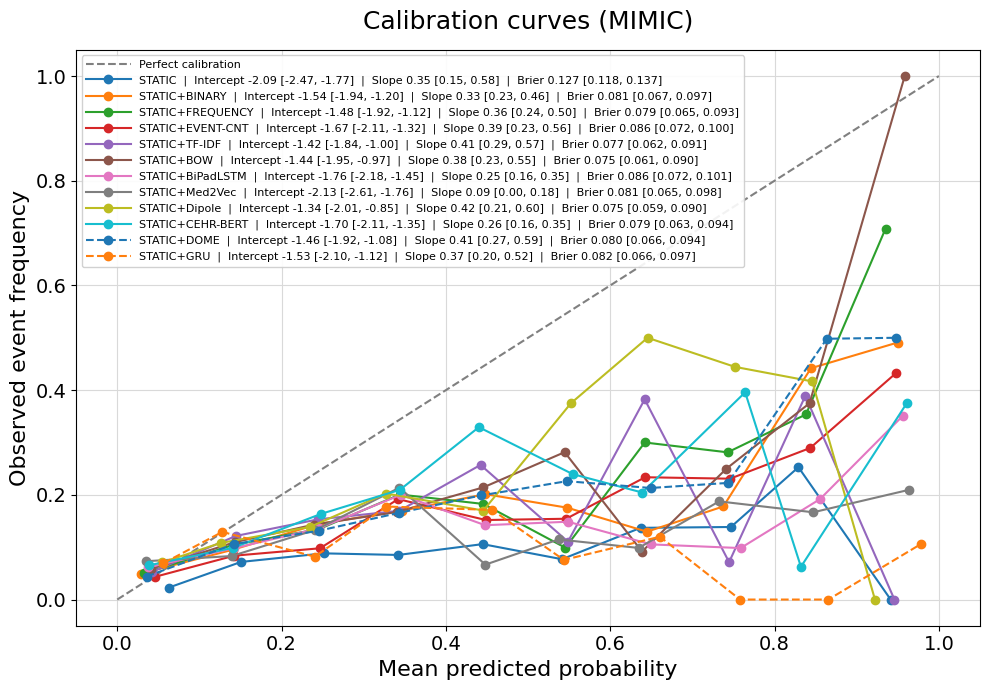

In [5]:
import pandas as pd
from scripts.plotting import plot_calibration_curves

summaries = {}
curves = {}
bands = {}
for m in methods.split(" "):
    calibration = pd.read_csv(f"{results_dir}/calibration_{dataset}_{m}_ITER{iter}.csv")
    summaries[m] = pd.read_csv(f"{results_dir}/summary_{dataset}_{m}_ITER{iter}.csv",index_col=0,)
    x = calibration["prob_pred"].to_numpy()
    curves[m] = (x,calibration["prob_true"].to_numpy(),)
    bands[m] = (x,calibration["ci95_low"].to_numpy(),calibration["ci95_high"].to_numpy(),)
    
fig, ax = plot_calibration_curves(
    methods=methods.split(' '),
    summary=summaries,
    curves=curves,
    dataset=dataset,
    bands=bands,
    figsize=(10, 7),
    legend_fontsize=8,
    show_ci_band=False,
)

## Radar plot

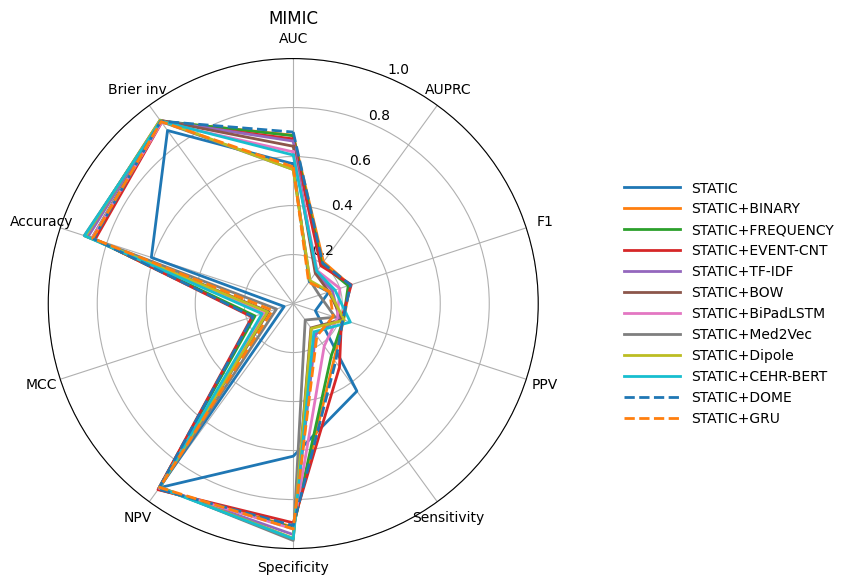

(<Figure size 1000x700 with 1 Axes>, <PolarAxes: title={'center': 'MIMIC'}>)

In [6]:
from scripts.plotting import plot_radar
import pandas as pd
table = pd.read_csv(f"{results_dir}/result_table_{dataset}_ITER{iter}.csv",index_col=0,).drop(columns=['Confusion matrix']).apply(lambda col: col.str[0:5])
table['Brier inv'] = table['Brier'].apply(lambda x: f"{1-float(x)}")
table.drop(columns=['Brier', 'Intercept', 'Slope'], inplace=True)
plot_radar(table,title=f"{dataset}")

## Statistical Analysis

In [17]:
results['STATIC+BINARY'][0].keys()

dict_keys(['AUC', 'AUPRC', 'F1', 'Sensitivity', 'Specificity', 'PPV', 'NPV', 'MCC', 'Accuracy', 'Brier', 'CM', 'OOF AUC', 'OOF AUPRC', 'OOF Sensitivity', 'OOF Specificity', 'OOF PPV', 'OOF NPV', 'CI95', 'y_true_oof', 'y_pred_oof', 'y_prob_oof', 'y_idx', 'calibration_prob_pred', 'calibration_prob_true'])

In [2]:
import pickle
import pandas as pd
from scripts.stats import stats_analysis
# Load results
meths = methods.split(' ')
meths.remove('STATIC')
results = {m: {} for m in meths}
for i in range(iter):
    for m in meths:
        meth = m.replace('+','_')
        path = (f"{results_dir}/results_{dataset}_{meth}_ITER{i}.pkl")
        with open(path, "rb") as f:
            results[m][i] = pickle.load(f)
friedman_df, ranking_table = stats_analysis(results, metrics, meths, iter)
friedman_df["p_value"] = pd.to_numeric(friedman_df["p_value"], errors="raise").astype(float)
display(friedman_df)
display(ranking_table)


=== FRIEDMAN TEST ===
Statistic: 205.7366
p-value: 1.03e-38
➡️ SIGNIFICANT global differences

=== FRIEDMAN TEST ===
Statistic: 169.4182
p-value: 3.66e-31
➡️ SIGNIFICANT global differences

=== FRIEDMAN TEST ===
Statistic: 95.6408
p-value: 4.05e-16
➡️ SIGNIFICANT global differences

=== FRIEDMAN TEST ===
Statistic: 17.8791
p-value: 5.70e-02
➡️ No global differences

=== FRIEDMAN TEST ===
Statistic: 166.5032
p-value: 1.47e-30
➡️ SIGNIFICANT global differences

=== FRIEDMAN TEST ===
Statistic: 152.5238
p-value: 1.13e-27
➡️ SIGNIFICANT global differences

=== FRIEDMAN TEST ===
Statistic: 121.8628
p-value: 2.12e-21
➡️ SIGNIFICANT global differences

=== FRIEDMAN TEST ===
Statistic: 55.7400
p-value: 2.30e-08
➡️ SIGNIFICANT global differences

=== FRIEDMAN TEST ===
Statistic: 110.3238
p-value: 4.59e-19
➡️ SIGNIFICANT global differences


,statistic,p_value,global_diff
AUC,205.736632,1.025236e-38,YES
AUPRC,169.418182,3.660713e-31,YES
F1,95.640837,4.047374e-16,YES
PPV,17.879053,5.703843e-02,NO
Sensitivity,166.503194,1.468131e-30,YES
Specificity,152.523805,1.127122e-27,YES
NPV,121.862781,2.118162e-21,YES
MCC,55.73998,2.296448e-08,YES
Accuracy,110.323774,4.590898e-19,YES


,AUC,AUPRC,F1,PPV,Sensitivity,Specificity,NPV,MCC,Accuracy
STATIC+DOME,1,1,1,1,1,9,1,2,7
STATIC+BINARY,1,1,1,1,2,9,1,1,7
STATIC+FREQUENCY,1,4,1,1,2,8,1,4,7
STATIC+EVENT-CNT,4,3,1,1,2,9,1,2,11
STATIC+TF-IDF,4,7,6,1,7,5,6,8,5
STATIC+BOW,6,4,6,1,9,2,6,7,1
STATIC+CEHR-BERT,7,8,6,1,6,2,6,5,1
STATIC+BiPadLSTM,8,4,5,1,5,7,5,5,7
STATIC+Med2Vec,9,9,11,1,11,1,11,10,1
STATIC+GRU,10,9,6,1,7,6,6,10,6


In [3]:
friedman_latex = friedman_df.copy()
friedman_latex["p_value"] = friedman_latex["p_value"].apply(
    lambda x: f"{x:.2e}"
)
friedman_latex["global_diff"] = friedman_latex["global_diff"].map({
    "YES": r"\checkmark",
    "NO": r"\ding{55}"
})
friedman_latex = friedman_latex.rename(columns={
    "statistic": "Statistic",
    "p_value": "$p$-value",
    "global_diff": "Difference"
})
friedman_latex = friedman_latex.T
latex_table = friedman_latex.T.to_latex(
    escape=False,
    caption="Friedman test results for all evaluation metrics.",
    label="tab:friedman",
    column_format="l" + "c"*len(friedman_latex.T.columns)
)
print(latex_table)

\begin{table}
\caption{Friedman test results for all evaluation metrics.}
\label{tab:friedman}
\begin{tabular}{lccc}
\toprule
 & Statistic & $p$-value & Difference \\
\midrule
AUC & 205.736632 & 1.03e-38 & \checkmark \\
AUPRC & 169.418182 & 3.66e-31 & \checkmark \\
F1 & 95.640837 & 4.05e-16 & \checkmark \\
PPV & 17.879053 & 5.70e-02 & \ding{55} \\
Sensitivity & 166.503194 & 1.47e-30 & \checkmark \\
Specificity & 152.523805 & 1.13e-27 & \checkmark \\
NPV & 121.862781 & 2.12e-21 & \checkmark \\
MCC & 55.739980 & 2.30e-08 & \checkmark \\
Accuracy & 110.323774 & 4.59e-19 & \checkmark \\
\bottomrule
\end{tabular}
\end{table}



In [39]:
print(ranking_table.drop(columns=['AUPRC', 'PPV', 'NPV', 'Accuracy']).to_latex())

\begin{tabular}{lrrrrr}
\toprule
 & AUC & F1 & Sensitivity & Specificity & MCC \\
\midrule
STATIC+EVENT-CNT & 1 & 1 & 1 & 11 & 1 \\
STATIC+DOME & 1 & 2 & 2 & 6 & 2 \\
STATIC+BINARY & 1 & 2 & 2 & 8 & 3 \\
STATIC+FREQUENCY & 1 & 4 & 4 & 6 & 4 \\
STATIC+TF-IDF & 5 & 7 & 6 & 8 & 8 \\
STATIC+BiPadLSTM & 6 & 5 & 4 & 8 & 6 \\
STATIC+BOW & 6 & 11 & 10 & 2 & 11 \\
STATIC+CEHR-BERT & 8 & 9 & 9 & 4 & 8 \\
STATIC+Med2Vec & 8 & 10 & 10 & 1 & 8 \\
STATIC+Dipole & 8 & 6 & 6 & 2 & 5 \\
STATIC+GRU & 11 & 7 & 8 & 5 & 7 \\
\bottomrule
\end{tabular}



## Memory/Time consumptions

In [4]:
import pandas as pd
from scripts.utils import highlight_best_values
df = pd.read_csv(f"{results_dir}/perf_{dataset}_ITER{iter}.csv", index_col=0)
df

,emb_train_time_s,emb_inference_time_s,emb_inference_ms_per_patient,emb_cpu_memory_delta_mb,emb_peak_gpu_memory_mb,emb_n_trainable_params,emb_n_total_params,clf_train_time_s,clf_inference_time_s,clf_inference_ms_per_patient,clf_cpu_memory_delta_mb
STATIC,nan±nan,nan±nan,nan±nan,nan±nan,nan±nan,nan±nan,nan±nan,0.119±0.053,0.002±0.003,0.016±0.019,0.903±4.965
BINARY,0.463±0.020,0.037±0.002,0.055±0.003,3121.110±350.288,nan±nan,6371.000±0.000,nan±nan,0.179±0.059,0.007±0.000,0.055±0.003,5.049±8.959
FREQUENCY,0.463±0.028,0.008±0.001,0.012±0.001,3115.925±349.397,nan±nan,6371.000±0.000,nan±nan,0.171±0.053,0.007±0.000,0.054±0.001,5.423±9.134
EVENT-CNT,0.012±0.001,0.000±0.000,0.000±0.000,3000.458±355.952,nan±nan,5.000±0.000,nan±nan,0.080±0.036,0.000±0.000,0.003±0.000,0.018±0.122
TF-IDF,0.075±0.024,0.020±0.001,0.029±0.001,3012.746±319.161,57.600±19.200,365309.940±6096.994,365309.940±6096.994,0.132±0.036,0.000±0.000,0.004±0.000,0.122±0.847
BOW,0.073±0.014,0.019±0.000,0.028±0.000,3012.961±318.513,57.600±19.200,362478.080±6049.731,362478.080±6049.731,0.134±0.026,0.000±0.000,0.004±0.000,0.004±0.018
BiPadLSTM,6.694±0.455,0.297±0.007,0.443±0.011,397.722±51.735,397.722±51.735,1848473.000±0.000,1848473.000±0.000,0.151±0.038,0.001±0.000,0.008±0.000,0.750±5.106
Med2Vec,70.980±8.901,0.275±0.065,0.410±0.096,3085.803±101.165,2053.368±441.129,2773447.000±0.000,2773447.000±0.000,0.103±0.026,0.001±0.000,0.005±0.000,0.092±0.452
Dipole,11.472±0.854,0.964±0.059,1.439±0.089,3091.919±83.045,1432.678±284.743,1952659.000±0.000,1952659.000±0.000,0.100±0.028,0.001±0.000,0.008±0.000,0.100±0.616
CEHR-BERT,2.676±0.119,0.104±0.003,0.155±0.004,3110.698±26.824,378.200±0.000,1688122.000±0.000,1688122.000±0.000,0.095±0.032,0.001±0.000,0.004±0.000,0.039±0.275


## SHAP analysis

In [ ]:
shap_dir = "experiment_shap"
%run notebook.py --dataname {dataset} --datafile data/INA_dataset.json \
    --results-dir {shap_dir} --mode shap --methods FREQUENCY DOME

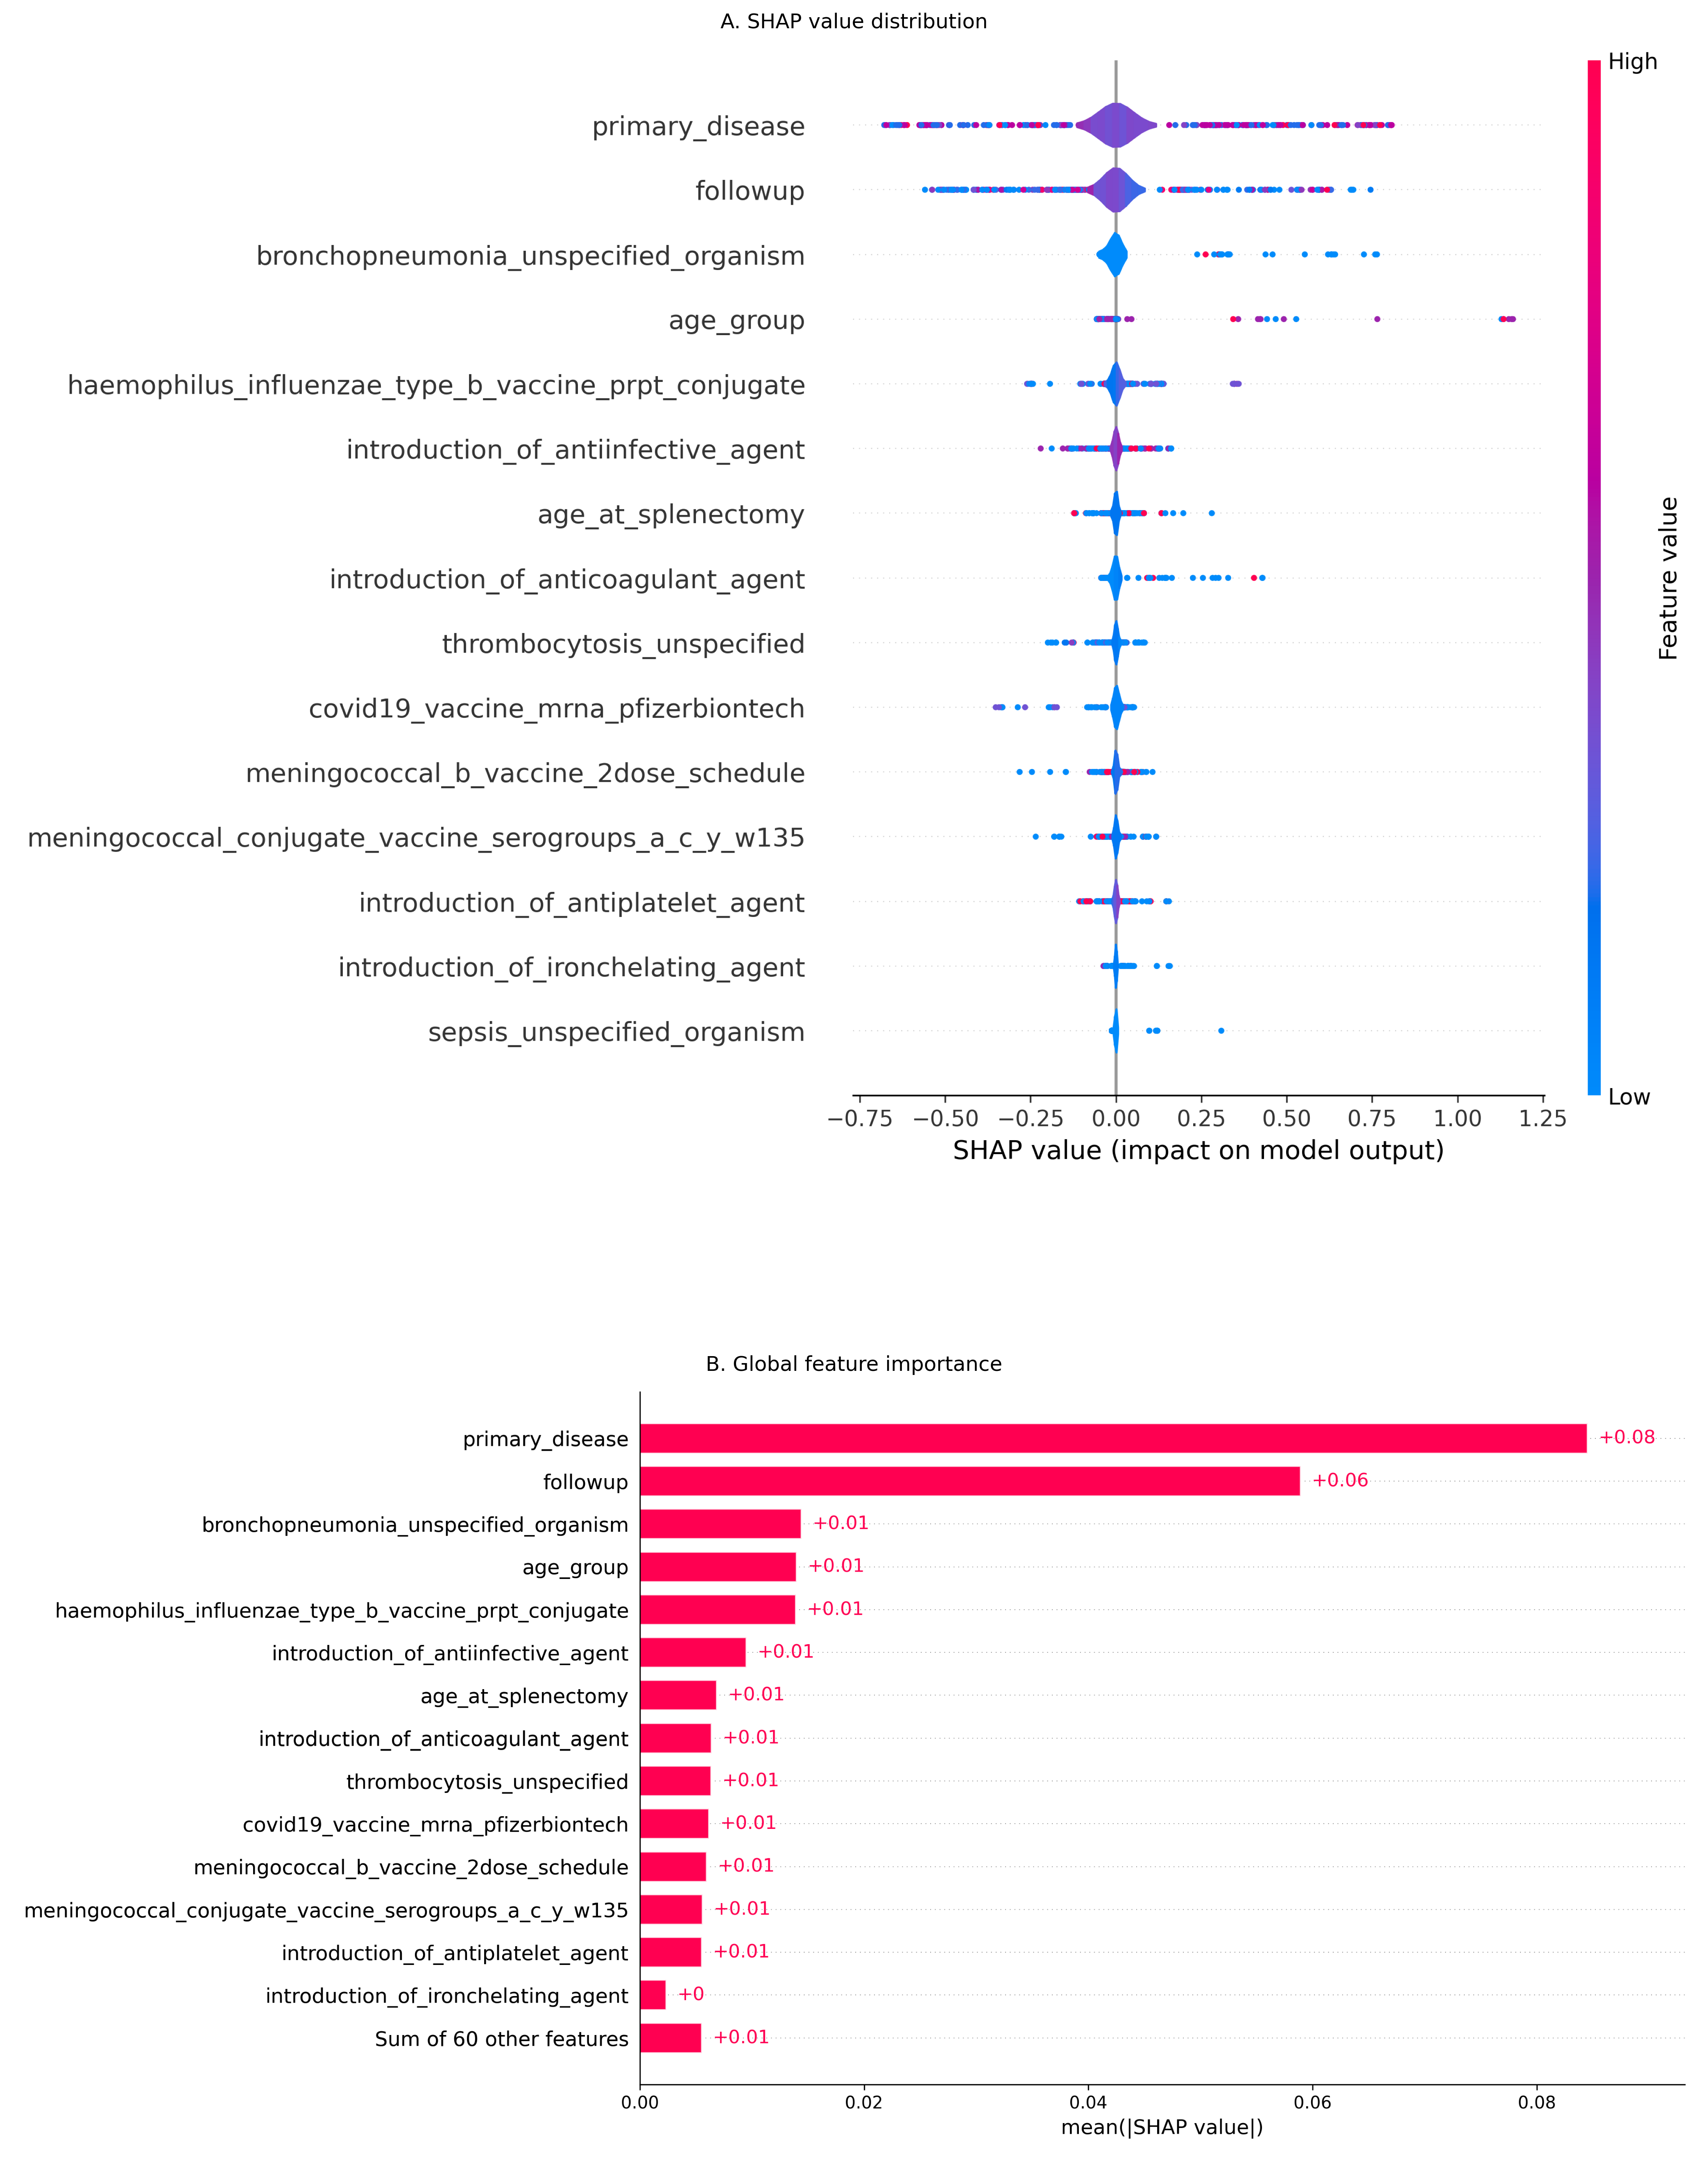

In [ ]:
from IPython.display import Image, display
display(Image(filename=f"{shap_dir}/{dataset}_DOME_shap.png"))